# COU 07506 – Week 1 – Lab 0: Setting Up the DSP Laboratory
**Name:** Iddy Omary  
**Registration number:** 240242439347  
**Date:** 25 November 2026  
**Group:** BEng24COE-2  
**Git repository:** local repo `COU07506-labs` and in github (https://github.com/iddyiom/COU07506-labs)

## Pre-lab
**Three devices that contain DSP and a signal each processes**
1. Smartphone – speech/voice picked up by the microphone (noise suppression, compression).
2. Digital hearing aid / earphones with noise cancelling – ambient sound.
3. Digital TV / set-top box or Wi-Fi router – the received radio-frequency (modulated) signal.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import signal
from scipy.io import wavfile
plt.rcParams["figure.figsize"] = (9, 3.5)

## Task 1.1 – Your first notebook (elementary sequences)

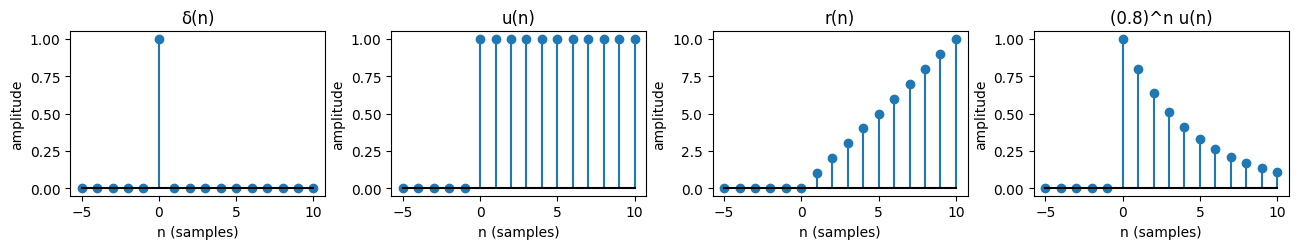

In [2]:
n = np.arange(-5, 11)
delta = (n == 0).astype(float)       # unit impulse
step  = (n >= 0).astype(float)       # unit step
ramp  = n * step                     # unit ramp
expo  = 0.8**n * step                # real exponential

fig, axes = plt.subplots(1, 4, figsize=(13, 2.6))
for ax, x, title in zip(axes, [delta, step, ramp, expo],
                        ["δ(n)", "u(n)", "r(n)", "(0.8)^n u(n)"]):
    ax.stem(n, x, basefmt="k-")
    ax.set_title(title); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

## Task 1.2 – Change the parameters

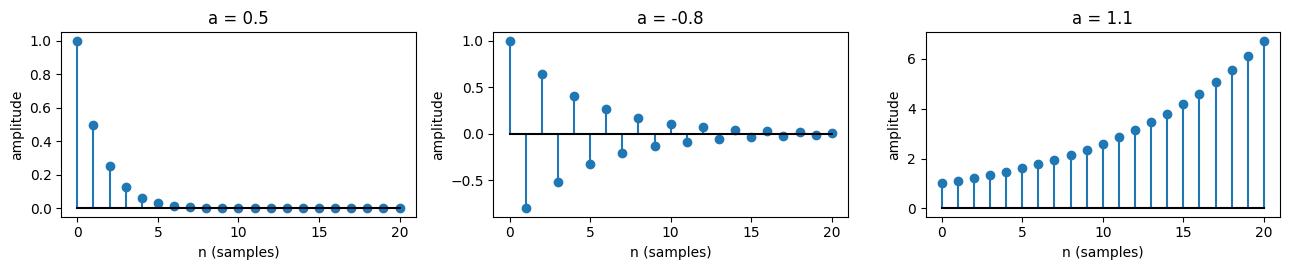

In [3]:
# (1) a^n u(n) for a = 0.5, -0.8, 1.1
n = np.arange(0, 21)
fig, axes = plt.subplots(1, 3, figsize=(13, 2.8))
for ax, a in zip(axes, [0.5, -0.8, 1.1]):
    ax.stem(n, a**n, basefmt="k-")
    ax.set_title(f"a = {a}"); ax.set_xlabel("n (samples)"); ax.set_ylabel("amplitude")
plt.tight_layout(); plt.show()

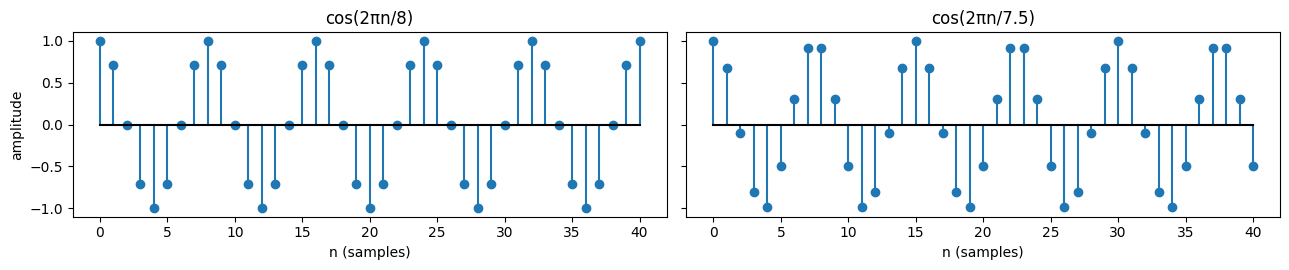

cos(2πn/8) repeats with N=8:   True
cos(2πn/7.5) repeats with N=8:  False
cos(2πn/7.5) repeats with N=15: True


In [4]:
# (2) cos(2*pi*n/8) vs cos(2*pi*n/7.5), 0 <= n <= 40
n = np.arange(0, 41)
x8, x75 = np.cos(2*np.pi*n/8), np.cos(2*np.pi*n/7.5)
fig, axes = plt.subplots(1, 2, figsize=(13, 2.8), sharey=True)
axes[0].stem(n, x8, basefmt="k-");  axes[0].set_title("cos(2πn/8)")
axes[1].stem(n, x75, basefmt="k-"); axes[1].set_title("cos(2πn/7.5)")
for ax in axes: ax.set_xlabel("n (samples)")
axes[0].set_ylabel("amplitude")
plt.tight_layout(); plt.show()
# numerical periodicity check
print("cos(2πn/8) repeats with N=8:  ", np.allclose(x8[:-8], x8[8:]))
print("cos(2πn/7.5) repeats with N=8: ", np.allclose(x75[:-8], x75[8:]))
print("cos(2πn/7.5) repeats with N=15:", np.allclose(x75[:-15], x75[15:]))

**Answer:** cos(2πn/8) repeats exactly (period 8 samples, since 2π/8 = 2π·(1/8) is a rational multiple of 2π).
cos(2πn/7.5) = cos(2π·(2/15)·n) is also periodic, but only with period 15 samples (two cycles of the "analogue" waveform fit in 15 samples), so it does *not* look periodic with period 8 or 7.5 – a discrete sinusoid is periodic only if its frequency f = k/N is rational, and the fundamental period is the smallest integer N. (Full explanation in Week 3.)

## Task 1.3 – Working with audio

fs = 16000 Hz, duration = 5.06 s, samples = 80896


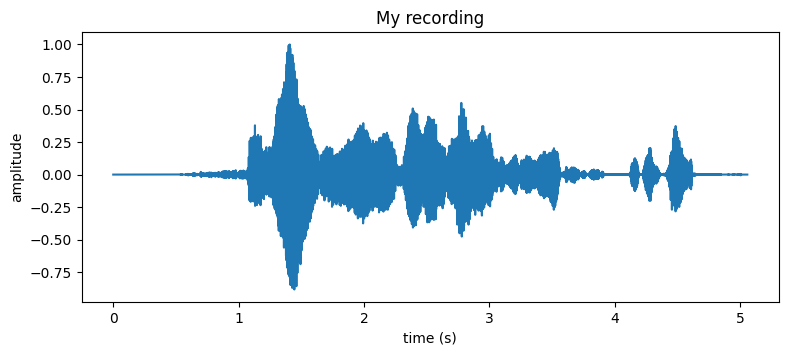

In [5]:
import os
fname = "my_voice.wav"                      # change to your file name
if os.path.exists(fname):
    fs, x = wavfile.read(fname)
    if x.ndim > 1:                          # stereo -> mono
        x = x.mean(axis=1)
    x = x / np.max(np.abs(x))               # normalise to [-1, 1]
else:                                       # fallback test signal
    fs = 16000
    t = np.arange(0, 2, 1/fs)
    x = 0.5*np.sin(2*np.pi*440*t) * np.exp(-t)
t = np.arange(len(x)) / fs
print(f"fs = {fs} Hz, duration = {len(x)/fs:.2f} s, samples = {len(x)}")
plt.plot(t, x); plt.xlabel("time (s)"); plt.ylabel("amplitude")
plt.title("My recording"); plt.show()

In [6]:
from IPython.display import Audio
Audio(x, rate=fs)

**Observation (Task 1.3):** my recording (`my_voice.wav`, converted from the phone's M4A file) is mono with fs = 16 000 Hz and lasts about 5.06 s (80 896 samples). The waveform shows bursts of high amplitude where I spoke and near-zero amplitude in the pauses before and after.

**1.** My recording has fs = **16 000 Hz** (see Task 1.3). One minute in mono needs 16 000 × 60 = **960 000 numbers** (about 1.9 MB at 16 bits each). A phone recording at 44.1 kHz would need 2 646 000, and at 48 kHz 2 880 000.

**2.** x(n) is defined only at integer values of n; nothing exists between samples. A stem plot shows each sample as its own point, whereas a continuous line would wrongly suggest values between the samples.

**3.** For a = 1.1 the impulse response grows without limit, so Σ|h(n)| = ∞. That violates **BIBO stability**: a bounded input would give an unbounded output (the system is unstable).